In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

import sys
!{sys.executable} -m pip install -U spacy spacy-lookups-data
!{sys.executable} -m spacy download en_core_web_sm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.2/33.2 MB 54.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.5/98.5 MB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 2.7 MB/s eta 0:00:00
  Attempting uninstall: srsly
    Found existing installation: srsly 2.5.2
    Uninstalling srsly-2.5.2:
      Successfully uninstalled srsly-2.5.2
  Attempting uninstall: confection
    Found existing installation: confection 0.1.5
    Uninstalling confection-0.1.5:
      Successfully uninstalled confection-0.1.5
  Attempting uninstall: thinc
    Found existing installation: thinc 8.3.10
    Uninstalling thinc-8.3.10:
      Successfully uninstalled thinc-8.3.10
  Attempting uninstall: weasel
    Found existing installation: weasel 0.4.3
    Uninstalling weasel-0.4.3:
      Successfully uninstalled weas

# Uploading  files getting to get relevant details from the trained file.

In [2]:

base_path = "/kaggle/input/datasets/ollatunji/aclimdb/aclImdb/train"
texts  = []
labels = []


for label in ["pos","neg"]:
    folder = os.path.join(base_path,label)
    for f_name in os.listdir(folder):
        if f_name.endswith('.txt'):
            with open(os.path.join(folder,f_name)) as f:
                text = f.read()
                text = text.replace("<br />", "\n\n")
                texts.append(text)
                if text.strip():
                    spacy_label = {
                       'cats' : {
                           'pos':'pos' == label,
                           'neg':'neg' == label
                       } 
                    }
                labels.append(spacy_label)

df = pd.DataFrame({"reviews":texts,"sentiments":labels})
df.head()

,reviews,sentiments
0,This was one of those wonderful rare moments i...,"{'cats': {'pos': True, 'neg': False}}"
1,Have you seen The Graduate? It was hailed as t...,"{'cats': {'pos': True, 'neg': False}}"
2,"I don't watch a lot of TV, except for The Offi...","{'cats': {'pos': True, 'neg': False}}"
3,Kubrick again puts on display his stunning abi...,"{'cats': {'pos': True, 'neg': False}}"
4,"First of all, I liked very much the central id...","{'cats': {'pos': True, 'neg': False}}"


In [3]:
import random

def load_trunc_training_data(data_directory: str = '/kaggle/input/datasets/ollatunji/aclimdb/aclImdb/train',split: float = 0.8, limit: int = 0) -> tuple:
    reviews = []
    for label in ['pos','neg']:
        labeled_directory = f"{data_directory}/{label}"
        for review in os.listdir(labeled_directory):
            if review.endswith('txt'):
                with open(f"{labeled_directory}/{review}") as f:
                    text = f.read()
                    text = text.replace("<br />","\n\n")
                    if text.strip():
                        label_for_spacy = {
                            "cats" : {
                                "pos":"pos" == label,
                                "neg":"neg" == label
                            }
                        }
                        reviews.append((text,label_for_spacy))
    random.shuffle(reviews)
    if limit:
        reviews = reviews[:limit]
    split_index = int(len(reviews) * split)
    return reviews[:split_index], reviews[split_index:]

In [4]:
train_data, test_data = load_trunc_training_data(limit=2500)
print(len(train_data),len(test_data))
train_data[0]

2000 500


("If you are going to attempt building tension in a film it is always a good idea not to build it beyond the point of total tedium.\n\n\n\nUnfortunately the Butcher Brothers haven't grasped this yet.\n\n\n\nThis film sucks, unlike the majority of its characters who (if you didn't work out they are vampires in the first few minutes then shame on you) preference stringing up the plentiful supply of 'no one knows where I am' cheerleader types and homosexual drifters that waft conveniently and with a fast food swagger, past their isolated door.\n\n\n\nThe only tiny bit of originality in the plot is how these vampires come to be vampires in the first place but the rest of it is ludicrous and sloppy.\n\n\n\nForced to up sticks (as opposed stakes) on a regular basis due to their penchant for filling their basement with bloodless corpses, they really are none too bright. If they fed their victims they could run their own little blood farm and it would cut down on the mortality rate, thereby al

In [5]:
#display first 200 characters
text,label = train_data[0]
text[:200],label

("If you are going to attempt building tension in a film it is always a good idea not to build it beyond the point of total tedium.\n\n\n\nUnfortunately the Butcher Brothers haven't grasped this yet.\n\n\n\nThi",
 {'cats': {'pos': False, 'neg': True}})

In [6]:
import spacy 
from spacy.training import Example 
from spacy.util import minibatch,compounding
import random

def evaluate_model(
    tokenizer, textcat, test_data: list
) -> dict:
    reviews, labels = zip(*test_data)
    docs = list(tokenizer.pipe(reviews))
    
    true_positives = 0
    false_positives = 1e-8  # Can't be 0 because of presence in denominator
    true_negatives = 0
    false_negatives = 1e-8
    
    for doc, label in zip(textcat.pipe(docs), labels):
        true_label = label["cats"]
        # ✅ Directly get pos score — no loop, no skip logic needed
        pos_score = doc.cats["pos"]
        predicted_positive = pos_score >= 0.5
        actually_positive = true_label["pos"] == 1.0
            
        # the info you need with just the pos label.
        if predicted_positive and actually_positive:
            true_positives += 1
        elif predicted_positive and not actually_positive:
            false_positives += 1
        elif not predicted_positive and not actually_positive:
            true_negatives += 1
        elif not predicted_positive and actually_positive:
            false_negatives += 1
    
    precision = true_positives / (true_positives + false_positives)
    recall = true_positives / (true_positives + false_negatives)
    f_score = 0 if precision + recall == 0 else 2 * (precision * recall) / (precision + recall)

    return {"precision": precision, "recall": recall, "f-score": f_score}

    print(f"  TP:{true_positives:.0f} FP:{false_positives:.0f} "
      f"TN:{true_negatives:.0f} FN:{false_negatives:.0f}")

In [7]:
!pip install spacy-lookups-data

2000 500
Beginning training
Iteration	Loss	Precision	Recall	F-score
0	28.4488	0.7143	0.7812	0.7463
  ↑ New best F-score: 0.7463 — saving checkpoint
1	13.3428	0.8150	0.8086	0.8118
  ↑ New best F-score: 0.8118 — saving checkpoint
2	5.6131	0.7373	0.9102	0.8147
  ↑ New best F-score: 0.8147 — saving checkpoint
3	2.6233	0.7238	0.8906	0.7986
4	2.7167	0.7810	0.8359	0.8075
5	1.6153	0.8455	0.7695	0.8057
6	1.0331	0.7794	0.8555	0.8156
  ↑ New best F-score: 0.8156 — saving checkpoint
7	0.6853	0.8374	0.8047	0.8207
  ↑ New best F-score: 0.8207 — saving checkpoint
8	0.3274	0.7889	0.8320	0.8099
9	0.3404	0.8437	0.7383	0.7875
10	0.3624	0.7684	0.8555	0.8096
11	0.2222	0.7267	0.8828	0.7972
12	0.1120	0.8067	0.8477	0.8267
  ↑ New best F-score: 0.8267 — saving checkpoint
13	0.1167	0.8286	0.7930	0.8104
14	0.1273	0.8451	0.7461	0.7925
15	0.2228	0.8313	0.7891	0.8096
16	0.1443	0.8285	0.7734	0.8000
17	0.0558	0.7912	0.8437	0.8166
18	0.1040	0.8565	0.6992	0.7699
19	0.2047	0.7971	0.8594	0.8271
  ↑ New best F-score: 0.82

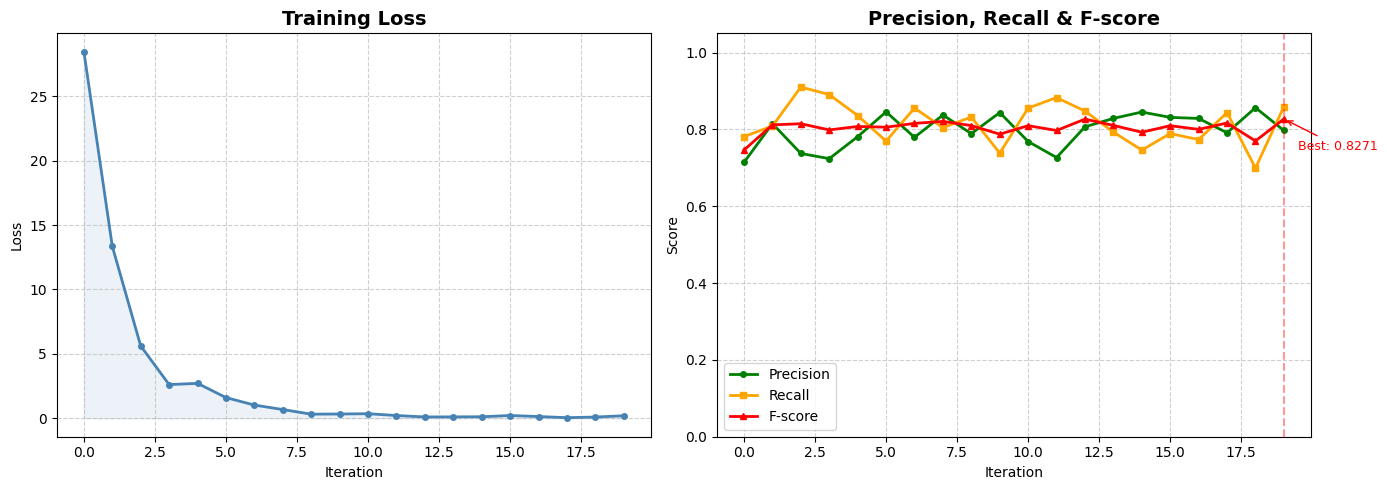

Plot saved to training_metrics.png


In [8]:
import matplotlib.pyplot as plt

def train_model(
    train_data: list,
    test_data: list,
    iterations: int = 20
) -> None:
    nlp = spacy.blank("en")

    if "textcat" not in nlp.pipe_names:
        textcat = nlp.add_pipe("textcat", last=True)
    else:
        textcat = nlp.get_pipe("textcat")

    textcat.add_label("pos")
    textcat.add_label("neg")

    def get_examples():
        return [
            Example.from_dict(nlp.make_doc(text), label)
            for text, label in train_data
        ]

    optimizer = nlp.initialize(get_examples)
    optimizer.learn_rate = 0.001

    print("Beginning training")
    print("Iteration\tLoss\tPrecision\tRecall\tF-score")

    batch_sizes = compounding(16.0, 64.0, 1.001)
    best_fscore = 0
    best_params = None

    # ✅ Track metrics for plotting
    losses_history = []
    precision_history = []
    recall_history = []
    fscore_history = []

    for i in range(iterations):
        loss = {}
        random.shuffle(train_data)
        batches = minibatch(train_data, size=batch_sizes)

        for batch in batches:
            texts, labels = zip(*batch)
            examples = [
                Example.from_dict(nlp.make_doc(text), label)
                for text, label in zip(texts, labels)
            ]
            nlp.update(examples, drop=0.1, sgd=optimizer, losses=loss)

        if optimizer.averages:
            cm = nlp.use_params(optimizer.averages)
        else:
            from contextlib import nullcontext
            cm = nullcontext()

        with cm:
            results = evaluate_model(
                tokenizer=nlp.tokenizer,
                textcat=textcat,
                test_data=test_data
            )
            fscore = results["f-score"]
            print(
                f"{i}\t{loss['textcat']:.4f}\t"
                f"{results['precision']:.4f}\t"
                f"{results['recall']:.4f}\t"
                f"{fscore:.4f}"
            )

            # ✅ Append to history lists
            losses_history.append(loss['textcat'])
            precision_history.append(results['precision'])
            recall_history.append(results['recall'])
            fscore_history.append(fscore)

            if fscore > best_fscore:
                best_fscore = fscore
                best_params = {
                    k: v.copy() for k, v in optimizer.averages.items()
                } if optimizer.averages else None
                print(f"  ↑ New best F-score: {best_fscore:.4f} — saving checkpoint")

    # Save best model
    if best_params:
        with nlp.use_params(best_params):
            nlp.to_disk("model_artifacts")
    else:
        nlp.to_disk("model_artifacts")
    print(f"Training complete. Best F-score: {best_fscore:.4f}")

    # ✅ Plot 1 — Loss
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(losses_history, color="steelblue", linewidth=2, marker="o", markersize=4)
    axes[0].set_title("Training Loss", fontsize=14, fontweight="bold")
    axes[0].set_xlabel("Iteration")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, linestyle="--", alpha=0.6)
    axes[0].fill_between(range(len(losses_history)), losses_history, alpha=0.1, color="steelblue")

    # ✅ Plot 2 — Precision, Recall, F-score
    axes[1].plot(precision_history, color="green",  linewidth=2, marker="o", markersize=4, label="Precision")
    axes[1].plot(recall_history,    color="orange", linewidth=2, marker="s", markersize=4, label="Recall")
    axes[1].plot(fscore_history,    color="red",    linewidth=2, marker="^", markersize=4, label="F-score")
    axes[1].set_title("Precision, Recall & F-score", fontsize=14, fontweight="bold")
    axes[1].set_xlabel("Iteration")
    axes[1].set_ylabel("Score")
    axes[1].set_ylim(0, 1.05)
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.6)

    # Mark best F-score point
    best_iter = fscore_history.index(best_fscore)
    axes[1].axvline(x=best_iter, color="red", linestyle="--", alpha=0.4)
    axes[1].annotate(
        f"Best: {best_fscore:.4f}",
        xy=(best_iter, best_fscore),
        xytext=(best_iter + 0.5, best_fscore - 0.08),
        fontsize=9,
        color="red",
        arrowprops=dict(arrowstyle="->", color="red")
    )

    plt.tight_layout()
    plt.savefig("training_metrics.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Plot saved to training_metrics.png")
    

print(len(train_data),len(test_data))
train_model(train_data, test_data, iterations=20)

In [9]:
TEST_REVIEW = """
Transcendently beautiful in moments outside the office, it seems almost
sitcom-like in those scenes. When Toni Colette walks out and ponders
life silently, it's gorgeous.<br /><br />The movie doesn't seem to decide
whether it's slapstick, farce, magical realism, or drama, but the best of it
doesn't matter. (The worst is sort of tedious - like Office Space with less humor.)
"""

def test_model(input_data: str=TEST_REVIEW):
    #  Load saved trained model
    loaded_model = spacy.load("model_artifacts")
    # Generate prediction
    parsed_text = loaded_model(input_data)
    # Determine prediction to return
    if parsed_text.cats["pos"] > parsed_text.cats["neg"]:
        prediction = "Positive"
        score = parsed_text.cats["pos"]
    else:
        prediction = "Negative"
        score = parsed_text.cats["neg"]
    print(
        f"Review text: {input_data}\nPredicted sentiment: {prediction}"
        f"\tScore: {score}"
    )

In [10]:
test_model()

Review text: 
Transcendently beautiful in moments outside the office, it seems almost
sitcom-like in those scenes. When Toni Colette walks out and ponders
life silently, it's gorgeous.<br /><br />The movie doesn't seem to decide
whether it's slapstick, farce, magical realism, or drama, but the best of it
doesn't matter. (The worst is sort of tedious - like Office Space with less humor.)

Predicted sentiment: Positive	Score: 0.9963435530662537
